# 3D reconstruction of plant shoot structure from 2D images

This notebook builds a 3D model of a plant shoot (stem, branches, leaves) from a set of overlapping photos. The model is the
starting point for measuring shoot architecture later. It runs the pipeline from the seminar **one stage at a time** so you can see
what each step produces, and it uses the modules in `src/recon3d/`, so everything here is also available from the command line.

## Dataset

> **Currently set to the Styrac sample dataset** (the professor's 53 photos of a figurine, Sony NEX-6) so the notebook can run
> while the shoot photos are being collected. When your own photos are ready, put them in `data/images/`, set
> `DATASET = "shoots"` in the next cell, and fill in the table below.

| | |
|---|---|
| Plant / genotype | *fill in* |
| Date photographed | *fill in* |
| Number of photos | *fill in* |
| Camera / phone | *fill in* |
| Background / surface | *fill in* |
| Lighting | *fill in* |

## Pipeline

| # | Stage | Module | What to check for shoots |
|---|---|---|---|
| 1 | Image collection | `images.py` | 20+ sharp photos, same size, no blur warnings |
| 2 | Feature extraction | `features.py` | Smooth leaves give few keypoints - look for keypoints on the stem and background, not only the leaves |
| 3 | Feature matching | `matching.py` | Overlapping leaves cause false matches - the match matrix should be bright near the diagonal |
| 4 | Structure from Motion | `sfm.py` | All cameras placed, reprojection error below 1 px |
| 5 | Dense point cloud | `dense.py` | Thin stems and petioles are often missing or fuzzy |
| 6-7 | Mesh reconstruction + refinement | `mesh.py` | Poisson tends to thicken thin stems into blobs - compare with the dense cloud |
| 8 | Mesh texturing | `texture.py` | Colours should match the photos, with no stripes or smearing |

## Run it

1. Put your photos in `data/images/`.
2. Select your `.venv` as the kernel (top right in VS Code) and click *Run All*.
3. Results are saved in `output/notebook_run/`.

The model has an **arbitrary scale** (SfM cannot know real size). To measure in real units, include a ruler or a scale marker
of known length in the photos.

In [1]:
import sys, os
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt
import open3d as o3d

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from recon3d import images, features, matching, sfm, dense, mesh, texture, render
from recon3d.synthetic import make_dataset

# ---- settings you can change -------------------------------------------------
DATASET = "styrac"     # "synthetic" (test cube) | "styrac" (professor's sample) | "shoots" (your own photos)
MAX_DIM = 1000         # longest side in pixels (smaller = faster; try 1600 for finer stems)
WINDOW = 8             # photos taken in order around the object: match only neighbours (faster).
                       # Use None to match every pair - only if the photos are NOT in order; in my tests matching all pairs
                       # was less accurate than matching neighbours, so prefer WINDOW when your photos are in shooting order.
# ------------------------------------------------------------------------------

IMAGE_DIR = {
    "synthetic": ROOT / "data" / "synthetic",
    "styrac":    ROOT / "data" / "styrac",
    "shoots":    ROOT / "data" / "images",
}[DATASET]

def find_photo_dir(d):
    """Return d, or the first sub-folder of d that actually contains photos (handles zips with an extra folder level)."""
    d = Path(d)
    if d.exists():
        if images.list_images(d):
            return d
        for sub in sorted(p for p in d.rglob("*") if p.is_dir()):
            if images.list_images(sub):
                return sub
    return d

if DATASET == "synthetic" and not (IMAGE_DIR / "ground_truth_camera_centers.npy").exists():
    make_dataset(IMAGE_DIR, n_images=36)      # fake photos of a textured cube
IMAGE_DIR = find_photo_dir(IMAGE_DIR)

n_photos = len(images.list_images(IMAGE_DIR)) if IMAGE_DIR.exists() else 0
assert n_photos >= 20, f"Found {n_photos} photos in {IMAGE_DIR} - put at least 20 there first."
print(f"dataset '{DATASET}': {n_photos} photos in {IMAGE_DIR}")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


dataset 'styrac': 53 photos in /tmp/work/3d-reconstruction/data/styrac


## Step 1 - Image collection

Load the photos and check them against the capture rules from the assignment: at least 20, sharp, and all the same size.
For shoot photos this step matters most, because everything later depends on it.

**Before running, make sure that:**
- the files are `.jpg` or `.png`. iPhone `.HEIC` photos are not read, so convert them first or set the camera to "Most Compatible".
- a mix of portrait and landscape photos is fine - each photo gets its own camera matrix - but keep the same zoom and lens.
- you did not change the zoom or switch lenses between shots.
- the plant fills roughly the middle 1/3 to 2/3 of each frame.

The check prints a warning for any photo that is much blurrier than the rest of your set. Retake those, because blurred leaves
produce few keypoints and later stages suffer.

Then we build a **camera matrix** `K` for each photo, which links pixels to 3D directions. A pixel `(u, v)` and a 3D point in camera
coordinates `(X, Y, Z)` are related by `u = f*X/Z + cx` and `v = f*Y/Z + cy`, where `f` is the focal length in pixels and
`(cx, cy)` is the image centre. We take `f` from the photo's EXIF data when it exists, and otherwise use a typical phone value.
A wrong `f` slightly bends the model, so check the printed focal length: for a phone it is usually about 0.8-1.3 times the
longest image side in pixels.

53 photos (16 portrait), sizes [(664, 1000), (1000, 664)], focal length ~ 1028 px
camera matrix of photo 0 =
 [[1.0278e+03 0.0000e+00 5.0000e+02]
 [0.0000e+00 1.0278e+03 3.3200e+02]
 [0.0000e+00 0.0000e+00 1.0000e+00]]


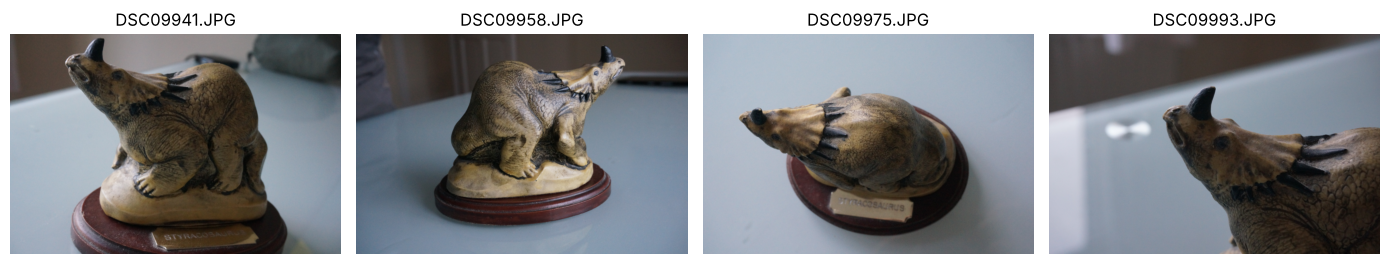

In [2]:
paths = images.list_images(IMAGE_DIR)
for w in images.check_images(IMAGE_DIR):
    print("WARNING:", w)
imgs = [images.load_image(p, MAX_DIM) for p in paths]
K = images.camera_matrices(paths, imgs)      # one 3x3 camera matrix per photo
f = K[0][0, 0]
sizes = sorted({(im.shape[1], im.shape[0]) for im in imgs})
n_portrait = sum(im.shape[0] > im.shape[1] for im in imgs)
print(f"{len(imgs)} photos ({n_portrait} portrait), sizes {sizes}, focal length ~ {f:.0f} px")
print("camera matrix of photo 0 =\n", K[0].round(1))

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, k in zip(axes, np.linspace(0, len(imgs) - 1, 4).astype(int)):
    ax.imshow(imgs[k][:, :, ::-1]); ax.set_title(paths[k].name); ax.axis("off")
plt.tight_layout(); plt.show()

## Step 2 - Feature extraction
SIFT finds *keypoints* - corners and blobs that look the same from different viewpoints - and describes each with
128 numbers (a *descriptor*). This is the "Feature detections" slide.

keypoints per photo (first 5): [3170, 2923, 1444, 1599, 1030]
descriptor shape for photo 0: (3170, 128)


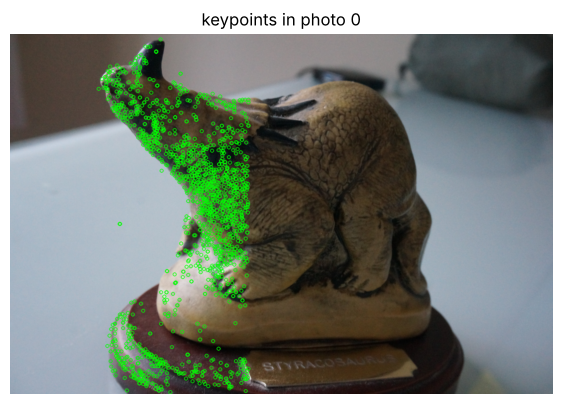

In [3]:
feats = [features.extract(im, n_features=4000) for im in imgs]
print("keypoints per photo (first 5):", [len(x.xy) for x in feats[:5]])
print("descriptor shape for photo 0:", feats[0].desc.shape)

plt.figure(figsize=(7, 5))
plt.imshow(features.draw_keypoints(imgs[0], feats[0], max_pts=1500)[:, :, ::-1])
plt.title("keypoints in photo 0"); plt.axis("off"); plt.show()

## Step 3 - Feature matching
For two photos, find which keypoint in photo B is the same physical point as each keypoint in photo A
(*corresponding pixels*). Two filters:

1. **Ratio test + mutual check** - keep a match only if it is clearly better than the runner-up and agrees both ways.
2. **Epipolar check (RANSAC)** - a true match must lie on the *epipolar line* predicted by one camera geometry
   (the epipolar geometry slide). Matches that disagree are outliers.

keypoints: 3170 / 1444
after ratio test + mutual check: 227 matches
after epipolar (RANSAC) check:    183 matches


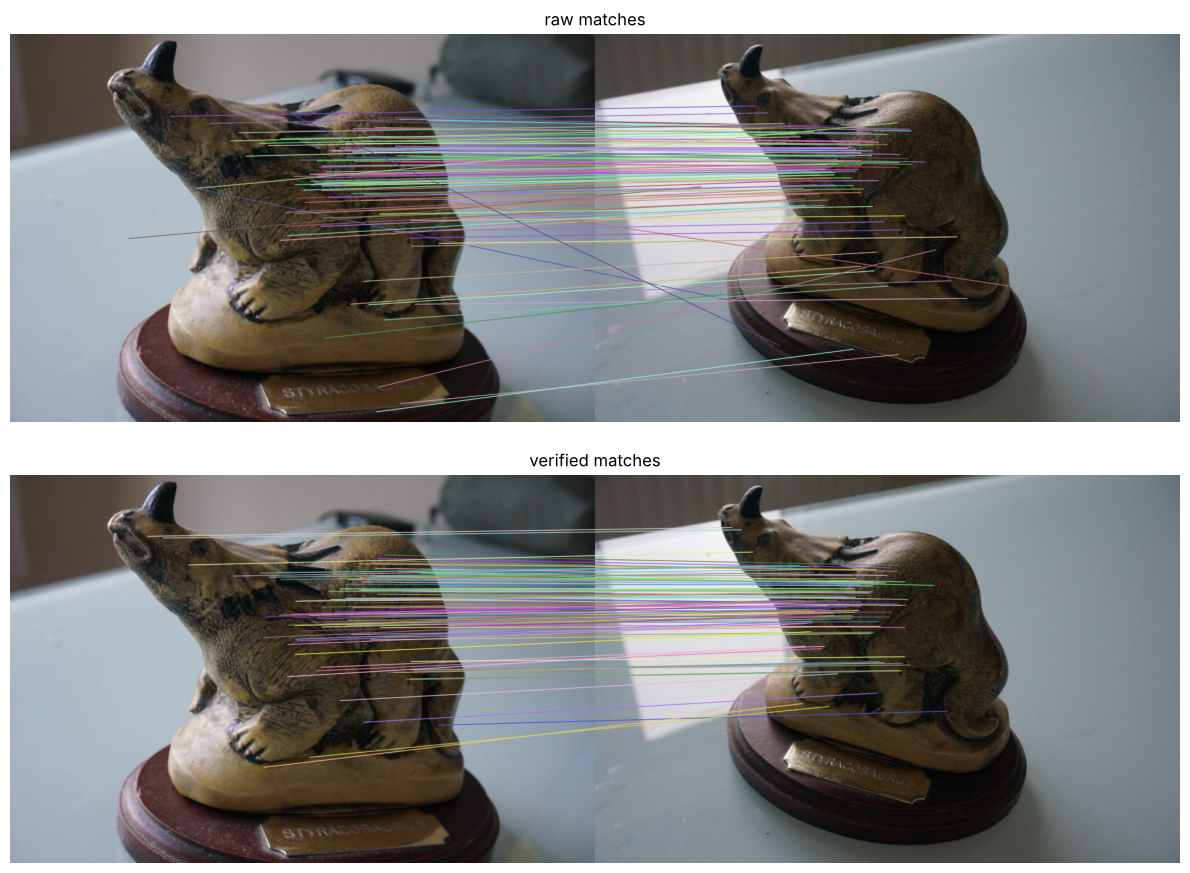

In [4]:
A, B = 0, 2
ia, ib = matching.match_pair(feats[A], feats[B])
ja, jb, F = matching.verify_pair(feats[A], feats[B], ia, ib)
print(f"keypoints: {len(feats[A].xy)} / {len(feats[B].xy)}")
print(f"after ratio test + mutual check: {len(ia)} matches")
print(f"after epipolar (RANSAC) check:    {len(ja)} matches")

fig, ax = plt.subplots(2, 1, figsize=(12, 9))
ax[0].imshow(matching.draw_matches(imgs[A], imgs[B], feats[A], feats[B], ia, ib, 100)[:, :, ::-1]); ax[0].set_title("raw matches"); ax[0].axis("off")
ax[1].imshow(matching.draw_matches(imgs[A], imgs[B], feats[A], feats[B], ja, jb, 100)[:, :, ::-1]); ax[1].set_title("verified matches"); ax[1].axis("off")
plt.tight_layout(); plt.show()

246 photo pairs with enough verified matches


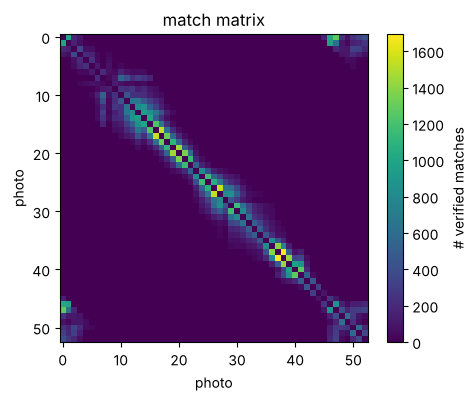

In [5]:
# match all neighbouring pairs (this is the slow part - about a minute for 36 photos)
all_matches = matching.match_all(feats, window=WINDOW)
print(len(all_matches), "photo pairs with enough verified matches")

# how connected is the photo set? (a good capture has a bright band around the diagonal)
n = len(imgs)
conn = np.zeros((n, n))
for (i, j), (a, b) in all_matches.items():
    conn[i, j] = conn[j, i] = len(a)
plt.figure(figsize=(5, 4)); plt.imshow(conn, cmap="viridis"); plt.colorbar(label="# verified matches")
plt.xlabel("photo"); plt.ylabel("photo"); plt.title("match matrix"); plt.show()

## Step 4 - Structure from Motion
Now the key idea: if the same point `X` is seen at pixel `x1` in camera 1 and `x2` in camera 2, the two viewing rays
intersect at `X` (the "compute 3D coordinates" slide). SfM does this for thousands of points *while also working out where
the cameras are*:

1. link matches into **tracks** (one physical point seen in many photos),
2. start from the best pair: relative pose from the **essential matrix**, then triangulate,
3. add one photo at a time using **PnP** (known 3D points -> pose),
4. **bundle adjustment** refines all cameras and points together to minimise reprojection error.

In [6]:
rec = sfm.run_sfm(feats, all_matches, K, verbose=True)
print()
print(f"cameras placed: {len(rec.poses)} / {len(imgs)}")
print(f"3D points:      {len(rec.points)}")
print(f"mean reprojection error: {rec.mean_reproj_error():.2f} px   (below 1 px is good)")

  22393 tracks


  initial pair (38,39) -> 1443 points


  registered image  37 (651 PnP inliers, +1166 points, 3/53 cams)
  registered image  36 (967 PnP inliers, +583 points, 4/53 cams)


  registered image  35 (617 PnP inliers, +317 points, 5/53 cams)
  registered image  41 (576 PnP inliers, +500 points, 6/53 cams)
  registered image  40 (850 PnP inliers, +854 points, 7/53 cams)
  registered image  42 (394 PnP inliers, +193 points, 8/53 cams)


  registered image  34 (294 PnP inliers, +225 points, 9/53 cams)
  registered image  33 (321 PnP inliers, +278 points, 10/53 cams)
  registered image  32 (403 PnP inliers, +242 points, 11/53 cams)
  registered image  31 (372 PnP inliers, +338 points, 12/53 cams)


...

  registered image   1 (838 PnP inliers, +475 points, 47/53 cams)
  registered image  46 (1017 PnP inliers, +552 points, 48/53 cams)


  registered image  52 (527 PnP inliers, +132 points, 49/53 cams)
  registered image  48 (459 PnP inliers, +235 points, 50/53 cams)
  registered image  49 (450 PnP inliers, +313 points, 51/53 cams)
  registered image  45 (245 PnP inliers, +38 points, 52/53 cams)


  registered image  44 (44 PnP inliers, +272 points, 53/53 cams)


  final: 53 cameras, 22008 points, mean reprojection error 0.36px

cameras placed: 53 / 53
3D points:      22008


mean reprojection error: 0.36 px   (below 1 px is good)


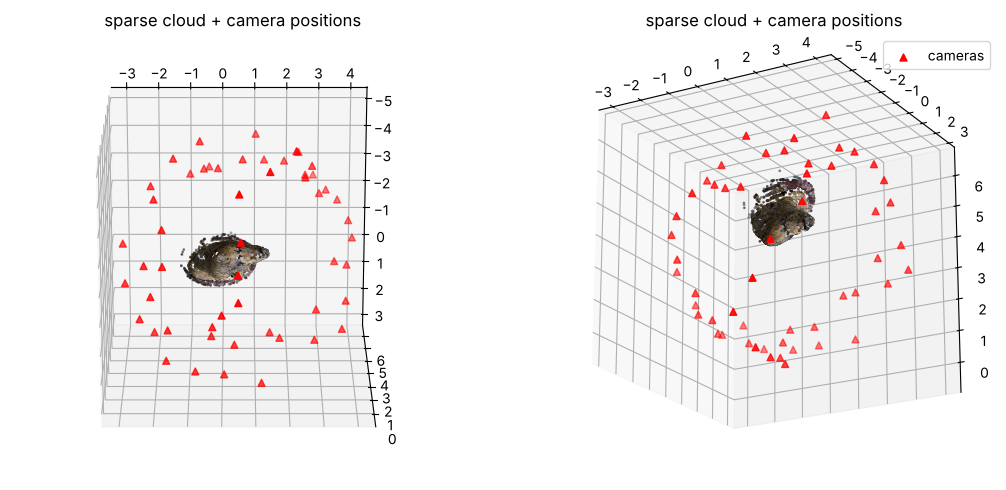

In [7]:
ids, sparse = rec.point_array()
centers = np.array([c.ravel() for c in rec.centers().values()])
cols = dense._sparse_colors(rec, imgs, ids)

fig = plt.figure(figsize=(11, 5))
for k, (elev, azim) in enumerate([(-70, -90), (-20, -60)]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    keep = np.linalg.norm(sparse - np.median(sparse, 0), axis=1) < 3 * np.percentile(np.linalg.norm(sparse - np.median(sparse, 0), axis=1), 80)
    ax.scatter(*sparse[keep].T, c=cols[keep], s=1)
    ax.scatter(*centers.T, c="red", s=25, marker="^", label="cameras")
    ax.view_init(elev=elev, azim=azim); ax.set_title("sparse cloud + camera positions")
    ax.set_box_aspect((1, 1, 1))
ax.legend(); plt.tight_layout(); plt.show()

**Check against the truth (synthetic data only).** The synthetic generator saved where it really placed the cameras, so we can
measure how accurate SfM is. SfM has an unknown overall scale/rotation, so we first align the two sets of positions.

In [8]:
truth_file = IMAGE_DIR / "ground_truth_camera_centers.npy"
if truth_file.exists():
    truth = np.load(truth_file)
    cam_ids = sorted(rec.poses)
    est = np.array([rec.centers()[i].ravel() for i in cam_ids])
    tru = truth[cam_ids]
    mu_e, mu_t = est.mean(0), tru.mean(0)
    U, sig, Vt = np.linalg.svd((tru - mu_t).T @ (est - mu_e) / len(est))
    E = np.diag([1, 1, np.sign(np.linalg.det(U @ Vt))]); R = U @ E @ Vt
    s = (sig * np.diag(E)).sum() / (est - mu_e).var(0).sum()
    aligned = (s * (R @ (est - mu_e).T)).T + mu_t
    err = np.linalg.norm(aligned - tru, axis=1)
    radius = np.linalg.norm(tru - mu_t, axis=1).mean()
    print(f"mean camera position error: {err.mean():.3f} units = {100 * err.mean() / radius:.2f}% of the orbit radius")
else:
    print("No ground truth for real photos - judge quality by reprojection error and by how the model looks.")

No ground truth for real photos - judge quality by reprojection error and by how the model looks.


## Step 5 - Dense point cloud
SfM only reconstructs points that had a keypoint. To fill in surfaces we run **stereo** on neighbouring camera pairs:
virtually rotate both cameras so matching pixels share an image row (*rectification*), compute a **disparity** for every
pixel, and convert to depth with `Z = f * baseline / disparity`.

stereo pair (10, 11): 9574 3D points


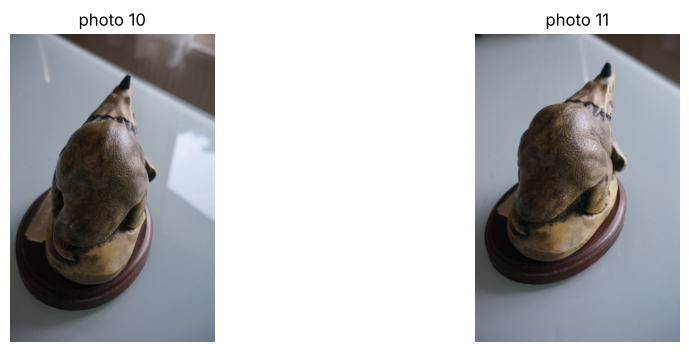

In [9]:
i, j = 10, 11
p, c = dense.stereo_pair(rec, imgs, i, j)
print(f"stereo pair ({i}, {j}): {len(p)} 3D points")

# the idea in one picture: nearby cameras -> the same scene shifted sideways
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(imgs[i][:, :, ::-1]); ax[0].set_title(f"photo {i}"); ax[0].axis("off")
ax[1].imshow(imgs[j][:, :, ::-1]); ax[1].set_title(f"photo {j}"); ax[1].axis("off")
plt.show()

dense cloud: 93,654 points  (sparse had 22,008)


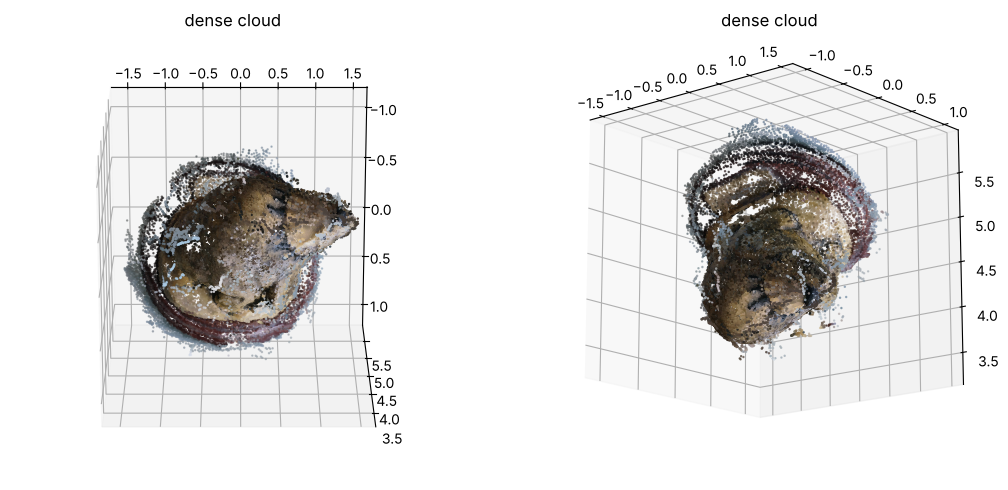

In [10]:
pcd = dense.dense_cloud(rec, imgs, verbose=False)
print(f"dense cloud: {len(pcd.points):,} points  (sparse had {len(rec.points):,})")

P, Cc = np.asarray(pcd.points), np.asarray(pcd.colors)
sel = np.random.default_rng(0).choice(len(P), min(60000, len(P)), replace=False)
fig = plt.figure(figsize=(11, 5))
for k, (elev, azim) in enumerate([(-70, -90), (-15, -50)]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.scatter(*P[sel].T, c=Cc[sel], s=0.6); ax.view_init(elev=elev, azim=azim)
    ax.set_box_aspect((1, 1, 1)); ax.set_title("dense cloud")
plt.tight_layout(); plt.show()

## Steps 6-7 - Mesh reconstruction and refinement
A point cloud has no surface. **Poisson surface reconstruction** fits a smooth watertight surface to the points (using their
estimated normals), then we trim made-up regions, remove floating fragments, simplify and smooth.

In [11]:
centers_list = list(rec.centers().values())
raw = mesh.reconstruct_mesh(pcd, centers_list, depth=8)
print(f"raw Poisson mesh: {len(raw.vertices):,} vertices, {len(raw.triangles):,} triangles")
ref = mesh.refine_mesh(raw)
print(f"refined mesh:     {len(ref.vertices):,} vertices, {len(ref.triangles):,} triangles")

raw Poisson mesh: 159,831 vertices, 317,683 triangles


refined mesh:     150,902 vertices, 299,999 triangles


## Step 8 - Mesh texturing
Each vertex takes its colour from the photos that see it most face-on.

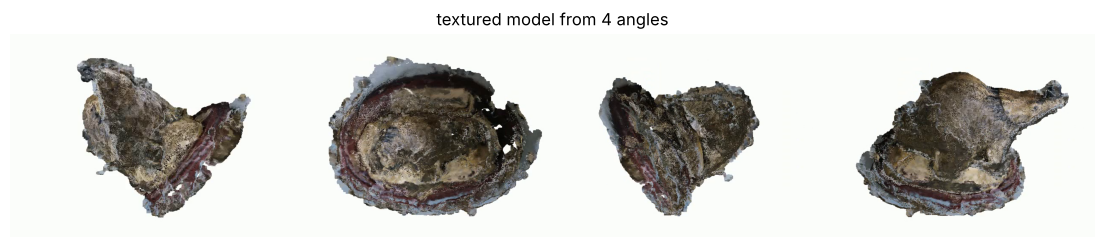

In [12]:
tex = texture.colorize_mesh(ref, rec, imgs)

# render a few views with the built-in turntable renderer
views = []
for k in range(4):
    render.turntable(tex, "_tmp.mp4", seconds=4, fps=1, size=(640, 480))
    cap = cv2.VideoCapture("_tmp.mp4"); cap.set(cv2.CAP_PROP_POS_FRAMES, k); ok, fr = cap.read(); cap.release()
    views.append(fr)
os.remove("_tmp.mp4")
plt.figure(figsize=(14, 3.6)); plt.imshow(cv2.hconcat(views)[:, :, ::-1]); plt.axis("off"); plt.title("textured model from 4 angles"); plt.show()

## Save the results
Writes the mesh (open in MeshLab / Blender) and the turntable video - the assignment's deliverable.

In [13]:
OUT = ROOT / "output" / f"{DATASET}_run"
OUT.mkdir(parents=True, exist_ok=True)
o3d.io.write_point_cloud(str(OUT / "dense.ply"), pcd)
o3d.io.write_triangle_mesh(str(OUT / "model.ply"), tex)
render.turntable(tex, str(OUT / "model_turntable.mp4"))
print("saved to", OUT)
for f_ in sorted(OUT.iterdir()):
    print(f"  {f_.name:22s} {f_.stat().st_size/1e6:6.1f} MB")

saved to /tmp/work/3d-reconstruction/output/styrac_run
  dense.ply                 2.5 MB
  model.ply                11.6 MB
  model_turntable.mp4      10.7 MB


## Things to try
* Change `MAX_DIM` to 600 and to 1600: how do speed and quality change?
* Delete half the photos (`paths = paths[::2]`) and re-run: what breaks first?
* Set `DATASET = "shoots"` and use your own photos. Which capture rule did you break when SfM places fewer cameras?
* Compare the final model with the Polycam version of the same photos.